In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("Zomato_Dataset.csv")

In [3]:
df.head()

,RestaurantID,RestaurantName,CountryCode,City,Address,Locality,LocalityVerbose,Cuisines,Currency,Has_Table_booking,Has_Online_delivery,Is_delivering_now,Switch_to_order_menu,Price_range,Votes,Average_Cost_for_two,Rating
0,6317637,Le Petit Souffle,162,Makati City,Third Floor| Century City Mall| Kalayaan Avenu...,Century City Mall| Poblacion| Makati City,Century City Mall| Poblacion| Makati City| Mak...,French| Japanese| Desserts,Botswana Pula(P),Yes,No,No,No,3,314,1100,4.8
1,6304287,Izakaya Kikufuji,162,Makati City,Little Tokyo| 2277 Chino Roces Avenue| Legaspi...,Little Tokyo| Legaspi Village| Makati City,Little Tokyo| Legaspi Village| Makati City| Ma...,Japanese,Botswana Pula(P),Yes,No,No,No,3,591,1200,4.5
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,Edsa Shangri-La| 1 Garden Way| Ortigas| Mandal...,Edsa Shangri-La| Ortigas| Mandaluyong City,Edsa Shangri-La| Ortigas| Mandaluyong City| Ma...,Seafood| Asian| Filipino| Indian,Botswana Pula(P),Yes,No,No,No,4,270,4000,4.4
3,6318506,Ooma,162,Mandaluyong City,Third Floor| Mega Fashion Hall| SM Megamall| O...,SM Megamall| Ortigas| Mandaluyong City,SM Megamall| Ortigas| Mandaluyong City| Mandal...,Japanese| Sushi,Botswana Pula(P),No,No,No,No,4,365,1500,4.9
4,6314302,Sambo Kojin,162,Mandaluyong City,Third Floor| Mega Atrium| SM Megamall| Ortigas...,SM Megamall| Ortigas| Mandaluyong City,SM Megamall| Ortigas| Mandaluyong City| Mandal...,Japanese| Korean,Botswana Pula(P),Yes,No,No,No,4,229,1500,4.8


In [4]:
df.shape

(9551, 17)

In [5]:
df.isnull().sum()

RestaurantID            0
RestaurantName          0
CountryCode             0
City                    0
Address                 0
Locality                0
LocalityVerbose         0
Cuisines                9
Currency                0
Has_Table_booking       0
Has_Online_delivery     0
Is_delivering_now       0
Switch_to_order_menu    0
Price_range             0
Votes                   0
Average_Cost_for_two    0
Rating                  0
dtype: int64

In [6]:
df['Cuisines'].value_counts().head(10)

Cuisines
North Indian                      936
North Indian| Chinese             511
Chinese                           354
Fast Food                         354
North Indian| Mughlai             334
Cafe                              299
Bakery                            218
North Indian| Mughlai| Chinese    197
Bakery| Desserts                  170
Street Food                       149
Name: count, dtype: int64

In [7]:
cuisine_rating = df.groupby('Cuisines')['Rating'].mean().sort_values(ascending=False)

cuisine_rating.head(10)

Cuisines
Burger| Bar Food| Steak            4.9
American| Burger| Grill            4.9
American| Caribbean| Seafood       4.9
American| Coffee and Tea           4.9
Mexican| American| Healthy Food    4.9
Italian| Bakery| Continental       4.9
BBQ| Breakfast| Southern           4.9
European| German                   4.9
Hawaiian| Seafood                  4.9
Sunda| Indonesian                  4.9
Name: Rating, dtype: float64

In [8]:
cuisine_analysis = df.groupby('Cuisines').agg(
    Restaurant_Count=('RestaurantName', 'count'),
    Average_Rating=('Rating', 'mean')
)

cuisine_analysis = cuisine_analysis.sort_values(
    'Restaurant_Count', ascending=False
)

cuisine_analysis.head(10)

,Restaurant_Count,Average_Rating
Cuisines,,
North Indian,936,2.146688
North Indian| Chinese,511,2.644814
Chinese,354,2.409322
Fast Food,354,2.474294
North Indian| Mughlai,334,3.008383
Cafe,299,3.048161
Bakery,218,2.327982
North Indian| Mughlai| Chinese,197,2.736041
Bakery| Desserts,170,2.635294


In [9]:
cuisine_analysis[cuisine_analysis['Restaurant_Count'] >= 20] \
    .sort_values('Average_Rating', ascending=False) \
    .head(10)

,Restaurant_Count,Average_Rating
Cuisines,,
American,31,3.732258
Italian,54,3.731481
Mexican,36,3.691667
Italian| Pizza,24,3.679167
Continental,21,3.614286
Cafe| Tea,20,3.475000
Fast Food| Burger,56,3.403571
Bakery| Desserts| Fast Food,63,3.398413
Desserts| Ice Cream,26,3.373077


In [11]:
import matplotlib.pyplot as plt

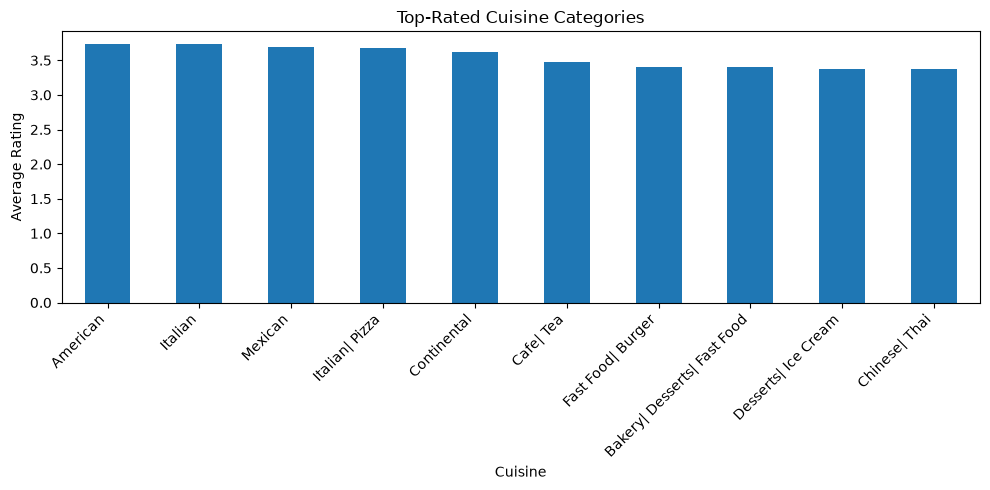

In [12]:
top_rated_cuisines = cuisine_analysis[
    cuisine_analysis['Restaurant_Count'] >= 20
].sort_values(
    'Average_Rating', ascending=False
).head(10)

top_rated_cuisines['Average_Rating'].plot(
    kind='bar',
    figsize=(10, 5),
    title='Top-Rated Cuisine Categories'
)

plt.xlabel('Cuisine')
plt.ylabel('Average Rating')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [13]:
top_rated_cuisines = cuisine_analysis[
    cuisine_analysis['Restaurant_Count'] >= 20
].sort_values('Average_Rating', ascending=False).head(10)

top_rated_cuisines

,Restaurant_Count,Average_Rating
Cuisines,,
American,31,3.732258
Italian,54,3.731481
Mexican,36,3.691667
Italian| Pizza,24,3.679167
Continental,21,3.614286
Cafe| Tea,20,3.475000
Fast Food| Burger,56,3.403571
Bakery| Desserts| Fast Food,63,3.398413
Desserts| Ice Cream,26,3.373077


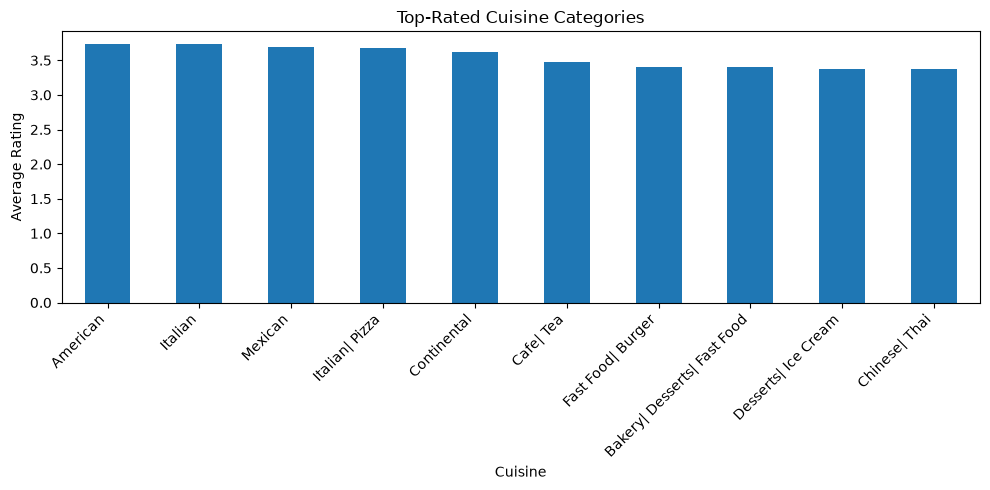

In [14]:
import matplotlib.pyplot as plt

top_rated_cuisines['Average_Rating'].plot(
    kind='bar',
    figsize=(10,5),
    title='Top-Rated Cuisine Categories'
)

plt.xlabel('Cuisine')
plt.ylabel('Average Rating')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [15]:
plt.savefig('top_rated_cuisines.png', bbox_inches='tight')

<Figure size 640x480 with 0 Axes>

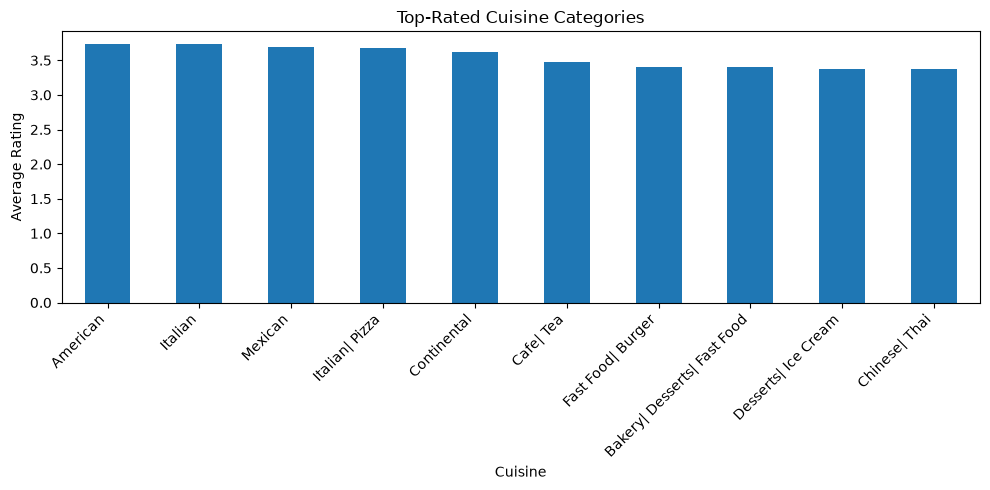

In [16]:
plt.figure(figsize=(10,5))

top_rated_cuisines['Average_Rating'].plot(
    kind='bar',
    title='Top-Rated Cuisine Categories'
)

plt.xlabel('Cuisine')
plt.ylabel('Average Rating')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

plt.savefig('top_rated_cuisines.png', bbox_inches='tight')
plt.show()